# Model results: first training run

Every number in this notebook is read from the CSV files under `outputs/`,
written by `python -m src.train.run` and `python -m src.eval.investigations`.
Nothing here trains a model.

**Evaluation design.** Repeated grouped, time-ordered cross-validation (`config/model.yaml`):

- **Folds and repeats.** 5 folds, repeated 3 times with a fresh agent grouping each time, giving 15 folds. Agents are assigned to folds by `StratifiedGroupKFold`, so no agent is ever split across folds.
- **Test rows.** Each fold's test set is its 70 agents' activations submitted on or after day 90.
- **Training rows.** Training uses the other agents' activations whose 8-day downstream window (days 0 to 7) had closed by day 90, so no training row carries a T7 feature or label observed during the test period.
- **Hyperparameter search.** A 12-candidate random search runs on an inner validation fold carved out of the training data under the same grouped, time-ordered rules. The outer test rows are never seen during search.
- **Resampling.** SMOTE is applied to training rows only, after splitting. A test intercepts every SMOTE call to check this.

**Models.**

- Four hand-written analyst rules, with no fitting.
- Logistic regression on the T7 feature set.
- XGBoost on the T7 feature set.
- XGBoost on the T0 feature set only.

"T7 feature set" means everything available seven days after submission: the 18 T0 features plus the 9 downstream features. Both XGBoost models are run with SMOTE and with `scale_pos_weight`, on the same folds.

**Reporting.** PR-AUC is the headline. Recall at 90% and 95% precision is the recall at the best threshold on that fold reaching that precision; it is a metric definition, not a decision threshold. Every metric is a mean with its standard deviation across the 15 folds, and every fold's prevalence is shown beside its scores. No calibration or decision-band work is done here.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.eval.results import MODEL_LABELS
from src.train.data import load_dataset

OUT = REPO_ROOT / "outputs"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)

summary = pd.read_csv(OUT / "cv_summary.csv")
formatted = pd.read_csv(OUT / "results_table_formatted.csv")
fold_metrics = pd.read_csv(OUT / "cv_fold_metrics.csv")
cv_folds = pd.read_csv(OUT / "cv_folds.csv")
paired = pd.read_csv(OUT / "paired_differences_summary.csv")
typology = pd.read_csv(OUT / "typology_recall_summary.csv")
rules = pd.read_csv(OUT / "rules_baseline_rule_statistics.csv")
diagnostics = pd.read_csv(OUT / "diagnostics.csv")

dataset = load_dataset()
label_lookup = pd.Series(dataset.labels, index=dataset.keys["activation_id"])
predictions = pd.read_parquet(OUT / "oof_predictions.parquet")
predictions["label"] = predictions["activation_id"].map(label_lookup).to_numpy()

# Chart styling: light chart surface, fixed categorical slots in display order
# (colour follows the model everywhere in this notebook), solid hairline grid.
SURFACE, INK, INK_2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MODEL_ORDER = ["rules_t7", "logreg_t7", "xgb_t7_smote", "xgb_t7_spw", "xgb_t0_smote", "xgb_t0_spw"]
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
COLOUR = dict(zip(MODEL_ORDER, SLOTS))
SHORT = {
    "rules_t7": "Rules (T7)", "logreg_t7": "Logistic regression (T7)",
    "xgb_t7_smote": "XGBoost T7, SMOTE", "xgb_t7_spw": "XGBoost T7, scale_pos_weight",
    "xgb_t0_smote": "XGBoost T0, SMOTE", "xgb_t0_spw": "XGBoost T0, scale_pos_weight",
}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "lines.linewidth": 2.0,
    "legend.frameon": False, "font.size": 10, "axes.titlesize": 11,
})
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"{predictions['model'].nunique()} models, {predictions.groupby(['repeat', 'fold']).ngroups} folds")

6 models, 15 folds


## The folds

One row per fold. `test_prevalence` differs between folds, so PR-AUC values are
only comparable alongside it. Each fold holds 70 test agents, of whom 3 to 5 are
systematic, which is why the spread across folds matters.

In [2]:
fold_view = cv_folds.copy()
fold_view.round(4)

,repeat,fold,n_train,train_prevalence,n_inner_train,n_inner_val,inner_val_positives,n_test,test_positives,test_prevalence,n_test_agents,test_agents_honest,test_agents_opportunistic,test_agents_systematic,test_positives_ghost,test_positives_sim_farming,test_positives_payout_gaming,test_positives_collusion
0,0,0,34250,0.0675,13027,3429,217,8768,632,0.0721,70,47,20,3,200,174,136,122
1,0,1,34274,0.0670,13093,3504,284,8900,657,0.0738,70,56,11,3,192,222,144,99
2,0,2,34134,0.0659,12959,3459,259,8899,763,0.0857,70,58,8,4,211,278,190,84
3,0,3,34227,0.0681,13157,3558,316,8768,631,0.0720,70,54,13,3,158,263,115,95
4,0,4,34211,0.0678,13051,3559,323,8832,703,0.0796,70,58,7,5,188,300,117,98
5,1,0,34112,0.0665,12967,3400,206,8715,621,0.0713,70,58,8,4,156,248,166,51
6,1,1,34317,0.0675,13092,3391,228,8881,666,0.0750,69,52,13,4,203,234,115,114
7,1,2,34254,0.0686,13018,3402,249,8843,695,0.0786,70,49,18,3,190,227,148,130
8,1,3,34201,0.0655,13038,3517,305,8937,727,0.0813,70,56,11,3,194,253,175,105
9,1,4,34212,0.0683,13063,3517,329,8791,677,0.0770,71,58,9,4,206,275,98,98


## Results table

Mean (standard deviation) across 15 folds. The prevalence column is the test
prevalence, the PR-AUC a random ranking would score.

In [3]:
formatted

,model,description,n_folds,prevalence,pr_auc,roc_auc,recall_at_p90,recall_at_p95
0,rules_t7,"Rules baseline (4 analyst rules, T7 time)",15,0.077 (0.004),0.364 (0.040),0.777 (0.017),0.086 (0.097),0.013 (0.007)
1,logreg_t7,"Logistic regression, T7 feature set",15,0.077 (0.004),0.708 (0.030),0.929 (0.011),0.366 (0.063),0.216 (0.108)
2,xgb_t7_smote,"XGBoost, T7 feature set, SMOTE",15,0.077 (0.004),0.761 (0.037),0.942 (0.015),0.502 (0.064),0.427 (0.060)
3,xgb_t7_spw,"XGBoost, T7 feature set, scale_pos_weight",15,0.077 (0.004),0.741 (0.041),0.936 (0.019),0.458 (0.064),0.361 (0.086)
4,xgb_t0_smote,"XGBoost, T0 feature set only, SMOTE",15,0.077 (0.004),0.680 (0.046),0.914 (0.024),0.399 (0.059),0.319 (0.064)
5,xgb_t0_spw,"XGBoost, T0 feature set only, scale_pos_weight",15,0.077 (0.004),0.657 (0.051),0.907 (0.028),0.337 (0.064),0.260 (0.074)


PR-AUC for every model in every fold, with that fold's prevalence and
number of systematic test agents.

In [4]:
pr_by_fold = fold_metrics.pivot_table(index=["repeat", "fold"], columns="model", values="pr_auc")[MODEL_ORDER]
pr_by_fold.insert(0, "test_prevalence", fold_metrics.groupby(["repeat", "fold"])["prevalence"].first())
pr_by_fold.insert(1, "test_agents_systematic", fold_metrics.groupby(["repeat", "fold"])["test_agents_systematic"].first())
pr_by_fold.round(3)

model        test_prevalence  test_agents_systematic  rules_t7  logreg_t7  xgb_t7_smote  xgb_t7_spw  xgb_t0_smote  xgb_t0_spw
repeat fold                                                                                                                  
0      0               0.072                       3     0.292      0.663         0.693       0.670         0.604       0.589
       1               0.074                       3     0.323      0.718         0.758       0.763         0.671       0.685
       2               0.086                       4     0.421      0.759         0.807       0.749         0.732       0.665
       3               0.072                       3     0.422      0.713         0.774       0.763         0.702       0.687
       4               0.080                       5     0.358      0.680         0.765       0.717         0.687       0.618
1      0               0.071                       4     0.350      0.725         0.779       0.776         0.729       0.719
       1               0.075                       4     0.323      0.712         0.762       0.762         0.681       0.670
       2               0.079                       3     0.377      0.703         0.724       0.704         0.635       0.613
       3               0.081                       3     0.422      0.720         0.782       0.753         0.706       0.667
       4               0.077                       4     0.348      0.695         0.772       0.771         0.674       0.678
2      0               0.080                       4     0.389      0.758         0.825       0.812         0.754       0.737
       1               0.070                       3     0.333      0.738         0.798       0.778         0.714       0.715
       2               0.076                       4     0.367      0.705         0.709       0.671         0.596       0.563
       3               0.077                       3     0.398      0.683         0.735       0.729         0.659       0.650
       4               0.080                       4     0.333      0.655         0.733       0.703         0.651       0.601

## Headline metrics

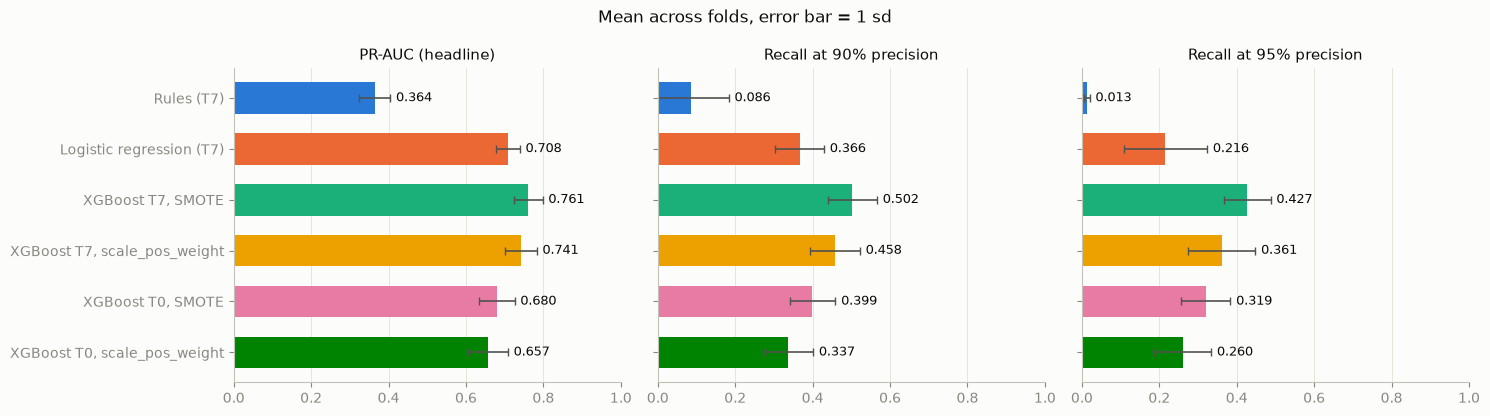

In [5]:
metrics = [("pr_auc", "PR-AUC (headline)"), ("recall_at_p90", "Recall at 90% precision"), ("recall_at_p95", "Recall at 95% precision")]
ordered = summary.set_index("model").loc[MODEL_ORDER]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
positions = np.arange(len(MODEL_ORDER))[::-1]
for axis, (metric, title) in zip(axes, metrics):
    axis.barh(positions, ordered[f"{metric}_mean"], height=0.62, color=[COLOUR[m] for m in MODEL_ORDER],
              xerr=ordered[f"{metric}_sd"], error_kw={"ecolor": INK_2, "elinewidth": 1.2, "capsize": 3})
    for y, mean, sd in zip(positions, ordered[f"{metric}_mean"], ordered[f"{metric}_sd"]):
        axis.text(mean + sd + 0.015, y, f"{mean:.3f}", va="center", fontsize=9, color=INK)
    axis.set(xlim=(0, 1), title=title)
    axis.grid(axis="y", visible=False)
axes[0].set_yticks(positions, [SHORT[m] for m in MODEL_ORDER])
fig.suptitle("Mean across folds, error bar = 1 sd", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "metric_summary.png", dpi=120)
plt.show()

## Precision-recall curves

Interpolated precision (the best precision reachable at that recall or higher)
on a common recall grid, averaged across the 15 folds. The shaded band is one
standard deviation across folds.

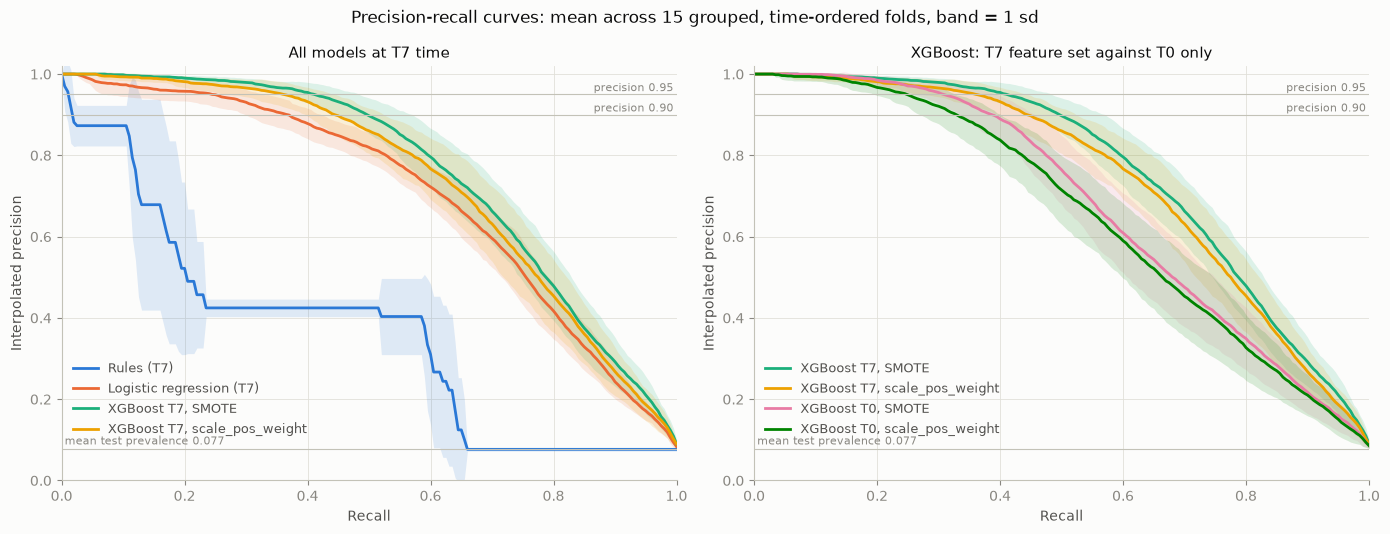

In [6]:
RECALL_GRID = np.linspace(0.0, 1.0, 201)


def interpolated_precision(labels: np.ndarray, scores: np.ndarray) -> np.ndarray:
    """Highest precision achievable at recall of at least r, on a fixed recall grid."""
    precision, recall, _ = precision_recall_curve(labels, scores)
    order = np.argsort(recall, kind="stable")
    recall, precision = recall[order], precision[order]
    best_from_here = np.maximum.accumulate(precision[::-1])[::-1]
    index = np.clip(np.searchsorted(recall, RECALL_GRID, side="left"), 0, len(recall) - 1)
    return best_from_here[index]


curves = {}
for (model, repeat, fold), group in predictions.groupby(["model", "repeat", "fold"]):
    curves.setdefault(model, []).append(
        interpolated_precision(group["label"].to_numpy(), group["score"].to_numpy(dtype=float))
    )
curve_mean = {m: np.mean(c, axis=0) for m, c in curves.items()}
curve_sd = {m: np.std(c, axis=0, ddof=1) for m, c in curves.items()}
mean_prevalence = fold_metrics.groupby(["repeat", "fold"])["prevalence"].first().mean()


def draw_curves(axis, models, title):
    for model in models:
        axis.fill_between(RECALL_GRID, curve_mean[model] - curve_sd[model],
                          curve_mean[model] + curve_sd[model], color=COLOUR[model], alpha=0.14, linewidth=0)
        axis.plot(RECALL_GRID, curve_mean[model], color=COLOUR[model], label=SHORT[model])
    for level in (0.90, 0.95):
        axis.axhline(level, color=BASELINE, linewidth=0.8)
        axis.text(0.995, level + 0.008, f"precision {level:.2f}", color=MUTED, fontsize=8, ha="right")
    axis.axhline(mean_prevalence, color=BASELINE, linewidth=0.8)
    axis.text(0.005, mean_prevalence + 0.012, f"mean test prevalence {mean_prevalence:.3f}", color=MUTED, fontsize=8)
    axis.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall", ylabel="Interpolated precision", title=title)
    axis.legend(loc="lower left", bbox_to_anchor=(0.0, 0.08), fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
draw_curves(axes[0], ["rules_t7", "logreg_t7", "xgb_t7_smote", "xgb_t7_spw"], "All models at T7 time")
draw_curves(axes[1], ["xgb_t7_smote", "xgb_t7_spw", "xgb_t0_smote", "xgb_t0_spw"], "XGBoost: T7 feature set against T0 only")
fig.suptitle("Precision-recall curves: mean across 15 grouped, time-ordered folds, band = 1 sd", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "pr_curves.png", dpi=120)
plt.show()

## SMOTE against scale_pos_weight (XGBoost)

Same folds, same hyperparameter candidates, separate searches. Differences are
scale_pos_weight minus SMOTE, per fold, then averaged, so a negative value means
SMOTE did better. `folds_first_better` counts the folds where the first-named
model won.

**Choice: SMOTE.** On the T7 feature set it beats `scale_pos_weight` in 14 of 15
folds on PR-AUC (by 0.020, sd 0.018). It also does better on recall at 90%
precision (+0.044) and at 95% (+0.066), and the same pattern holds on the T0
set. Three caveats keep this a narrow choice:

- **The comparison mixes method with strength.** SMOTE here raises the minority
  to 0.30 of the majority, about a 4x upweighting. `scale_pos_weight` is set to
  the full negative-to-positive ratio of the training split, about 14x. Part of
  the gap may be strength rather than method; a strength-matched
  `scale_pos_weight` has not been run.
- **SMOTE creates rows that could never be observed.** It interpolates binary
  flags into fractional values such as 0.4 for `activation_method_is_manual_entry`.
- **SMOTE adds a random step,** one more thing to seed and record.

In [7]:
paired.set_index("comparison").round(4).T

comparison,T7: scale_pos_weight minus SMOTE,T0: scale_pos_weight minus SMOTE,SMOTE: T7 minus T0,scale_pos_weight: T7 minus T0
n_folds,15.0000,15.0000,15.0000,15.0000
pr_auc_diff_mean,-0.0196,-0.0225,0.0813,0.0843
pr_auc_diff_sd,0.0184,0.0245,0.0140,0.0140
pr_auc_folds_first_better,1.0000,3.0000,15.0000,15.0000
roc_auc_diff_mean,-0.0067,-0.0068,0.0287,0.0287
roc_auc_diff_sd,0.0049,0.0085,0.0092,0.0101
roc_auc_folds_first_better,1.0000,3.0000,15.0000,15.0000
recall_at_p90_diff_mean,-0.0443,-0.0622,0.1030,0.1210
recall_at_p90_diff_sd,0.0514,0.0403,0.0355,0.0294
recall_at_p90_folds_first_better,3.0000,0.0000,15.0000,15.0000


## T0 against T7: the escrow hold window

Stated plainly: **XGBoost on T0 features alone already achieves most of the
ranking performance.** With SMOTE, T0 scores PR-AUC 0.680 (sd 0.046) against
0.761 (sd 0.037) for the T7 feature set, which is 89% of the T7 value from
information available the moment an activation is submitted. It is also close to
logistic regression using every T7 feature (0.708).

The hold window's gain is consistent but moderate:

- **Every fold.** T7 beats T0 in all 15 folds, by 0.081 PR-AUC (sd 0.014).
- **Recall at 90% precision.** It rises from 0.399 to 0.502, so about a quarter
  more fraud is caught at the same precision.
- **Where the gain comes from.** Weighting each typology's recall gain at 90%
  precision by its positives per fold, about half of the extra frauds caught are
  ghost activations and about a third are sim farming. Collusion and payout
  gaming each contribute under a tenth (see the typology breakdown below).

Whether a 0.08 PR-AUC gain justifies holding every payout for seven days is a
business judgement this notebook cannot make. The result does not support a
claim that the hold window is essential for detection overall. It supports a
narrower claim: the hold window roughly doubles recall on ghost activations,
whose tells are downstream, and adds a smaller gain on sim farming.

Each point in the scatter below is one fold. A point above the diagonal is a
fold where T7 beat T0.

In [8]:
comparison = summary.set_index("model").loc[
    ["xgb_t7_smote", "xgb_t0_smote", "xgb_t7_spw", "xgb_t0_spw"],
    ["pr_auc_mean", "pr_auc_sd", "recall_at_p90_mean", "recall_at_p90_sd", "recall_at_p95_mean", "recall_at_p95_sd"],
]
comparison.round(3)

,pr_auc_mean,pr_auc_sd,recall_at_p90_mean,recall_at_p90_sd,recall_at_p95_mean,recall_at_p95_sd
model,,,,,,
xgb_t7_smote,0.761,0.037,0.502,0.064,0.427,0.060
xgb_t0_smote,0.680,0.046,0.399,0.059,0.319,0.064
xgb_t7_spw,0.741,0.041,0.458,0.064,0.361,0.086
xgb_t0_spw,0.657,0.051,0.337,0.064,0.260,0.074


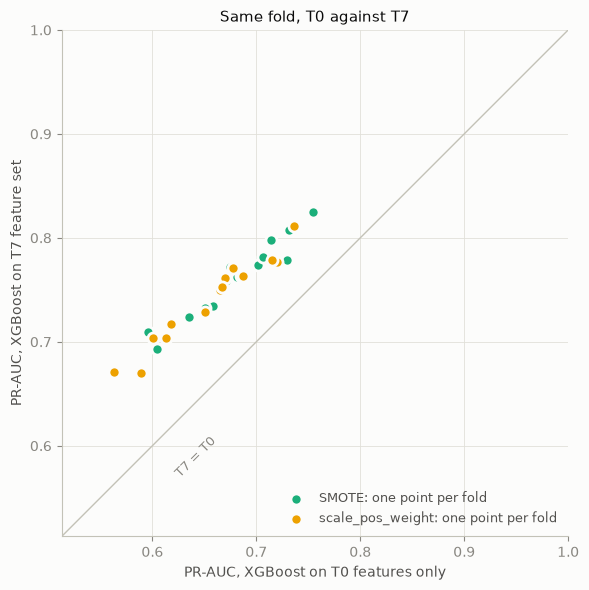

In [9]:
fig, axis = plt.subplots(figsize=(6.2, 6))
indexed = fold_metrics.set_index(["model", "repeat", "fold"])["pr_auc"]
for method, t7_model, t0_model in (("SMOTE", "xgb_t7_smote", "xgb_t0_smote"), ("scale_pos_weight", "xgb_t7_spw", "xgb_t0_spw")):
    axis.scatter(indexed.loc[t0_model], indexed.loc[t7_model], s=64, color=COLOUR[t7_model],
                 edgecolor=SURFACE, linewidth=2, label=f"{method}: one point per fold", zorder=3)
axis.plot([0, 1], [0, 1], color=BASELINE, linewidth=1)
axis.text(0.62, 0.57, "T7 = T0", color=MUTED, fontsize=9, rotation=45)
low = min(indexed.loc[["xgb_t0_smote", "xgb_t0_spw"]].min(), indexed.loc[["xgb_t7_smote", "xgb_t7_spw"]].min()) - 0.05
axis.set(xlim=(max(low, 0), 1), ylim=(max(low, 0), 1), xlabel="PR-AUC, XGBoost on T0 features only",
         ylabel="PR-AUC, XGBoost on T7 feature set", title="Same fold, T0 against T7")
axis.set_aspect("equal")
axis.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "t0_vs_t7_by_fold.png", dpi=120)
plt.show()

## Per-typology recall (chosen model)

Recall within each fraud typology at the fold's overall 90% and 95% precision
operating points, for XGBoost with SMOTE on the T7 set and its T0-only
counterpart. `n_positive_min` is the fewest positives of that typology in any
single test fold; collusion drops to 51, so its per-fold recall is the noisiest
number here.

- **Sim farming** is caught best: recall 0.79 at 90% precision, and already 0.70 at T0, from device sharing, velocity, network and SIM-age signals.
- **Ghost** activations depend on the hold window: recall 0.21 at T0 and 0.40 at T7.
- **Payout gaming** gains almost nothing from waiting (0.40 at T0, 0.43 at T7). Part of that T0 strength is a generator defect, described at the end of this notebook.
- **Collusion** is essentially undetected: 0.08 recall at 90% precision, even with T7. The customer is real, the submission is ordinary, and the downstream drop-off overlaps genuine trial-then-lapse customers by design.

In [10]:
CHOSEN = "smote"  # imbalance method chosen from the paired comparison above
typology_view = typology[typology["model"].isin(["xgb_t7_" + CHOSEN, "xgb_t0_" + CHOSEN])]
typology_view.pivot_table(
    index=["precision_target", "typology"], columns="model",
    values=["recall_mean", "recall_sd", "n_positive_mean", "n_positive_min"],
).round(3)

n_positive_mean              n_positive_min               recall_mean                 recall_sd             
model                             xgb_t0_smote xgb_t7_smote   xgb_t0_smote xgb_t7_smote xgb_t0_smote xgb_t7_smote xgb_t0_smote xgb_t7_smote
precision_target typology                                                                                                                  
0.90             collusion                99.6         99.6           51.0         51.0        0.033        0.077        0.018        0.047
                 ghost                   189.8        189.8          156.0        156.0        0.206        0.402        0.046        0.078
                 payout_gaming           140.4        140.4           98.0         98.0        0.395        0.433        0.080        0.083
                 sim_farming             247.4        247.4          174.0        174.0        0.695        0.787        0.109        0.069
0.95             collusion                99.6         99.6           51.0         51.0        0.011        0.035        0.011        0.029
                 ghost                   189.8        189.8          156.0        156.0        0.116        0.305        0.037        0.078
                 payout_gaming           140.4        140.4           98.0         98.0        0.333        0.356        0.086        0.071
                 sim_farming             247.4        247.4          174.0        174.0        0.587        0.717        0.131        0.087

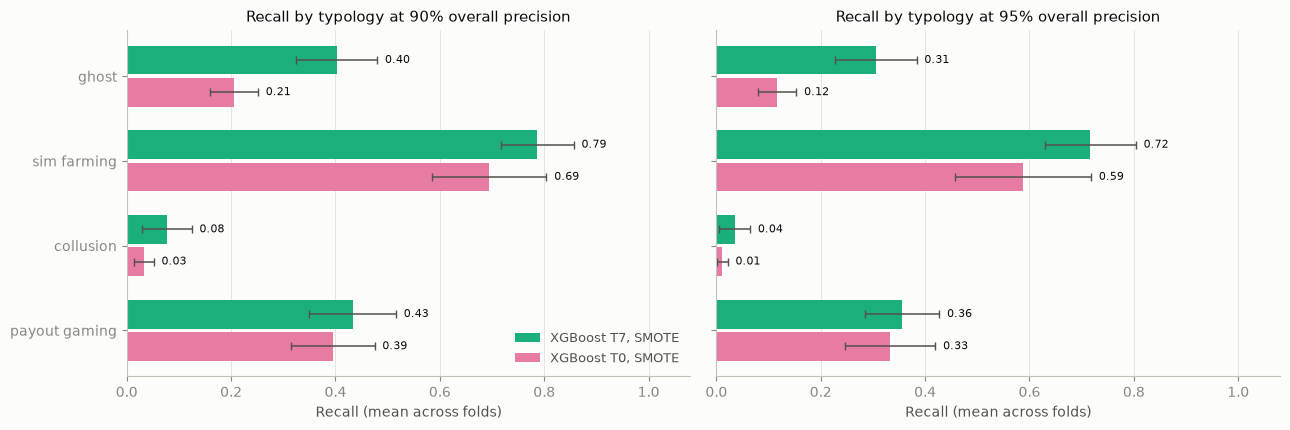

In [11]:
typologies = ["ghost", "sim_farming", "collusion", "payout_gaming"]
models = ["xgb_t7_" + CHOSEN, "xgb_t0_" + CHOSEN]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for axis, target in zip(axes, (0.90, 0.95)):
    subset = typology[(typology["precision_target"] == target)].set_index(["model", "typology"])
    base = np.arange(len(typologies))[::-1]
    for offset, model in zip((0.19, -0.19), models):
        rows = subset.loc[model].reindex(typologies)
        axis.barh(base + offset, rows["recall_mean"], height=0.34, color=COLOUR[model], label=SHORT[model],
                  xerr=rows["recall_sd"], error_kw={"ecolor": INK_2, "elinewidth": 1.1, "capsize": 3})
        for y, mean, sd in zip(base + offset, rows["recall_mean"], rows["recall_sd"]):
            axis.text(mean + sd + 0.015, y, f"{mean:.2f}", va="center", fontsize=8, color=INK)
    axis.set(xlim=(0, 1.08), title=f"Recall by typology at {target:.0%} overall precision", xlabel="Recall (mean across folds)")
    axis.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(typologies))[::-1], [t.replace("_", " ") for t in typologies])
axes[0].legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "typology_recall.png", dpi=120)
plt.show()

Mean recall by typology for every model, for reference.

In [12]:
typology.pivot_table(index=["precision_target", "typology"], columns="model", values="recall_mean")[MODEL_ORDER].round(3)

model                           rules_t7  logreg_t7  xgb_t7_smote  xgb_t7_spw  xgb_t0_smote  xgb_t0_spw
precision_target typology                                                                              
0.90             collusion         0.003      0.056         0.077       0.064         0.033       0.025
                 ghost             0.053      0.300         0.402       0.372         0.206       0.156
                 payout_gaming     0.029      0.413         0.433       0.390         0.395       0.355
                 sim_farming       0.177      0.518         0.787       0.720         0.695       0.588
0.95             collusion         0.000      0.027         0.035       0.023         0.011       0.008
                 ghost             0.000      0.138         0.305       0.246         0.116       0.087
                 payout_gaming     0.001      0.327         0.356       0.304         0.333       0.277
                 sim_farming       0.035      0.293         0.717       0.617         0.587       0.481

## The rules baseline, rule by rule

Each rule evaluated on every test-period row once. The rules were written from
the typology descriptions without fitting. Together they score PR-AUC 0.364, and
their recall at 90% precision has a standard deviation (0.097) larger than its
mean (0.086). The rule score takes only five values (0 to 4 rules fired), so the
90% precision point is often unreachable or sits on a single coarse step.

In [13]:
rules.round(4)

,rule,description,fired_share,precision,recall
0,volume_burst_dead_customer,Agent submitted five or more activations in 24...,0.0933,0.4304,0.5236
1,shared_device_fresh_sim,Device used by three or more agents in 30 days...,0.0132,0.5969,0.1028
2,keyed_in_no_proof_no_use,"Keyed in by hand, no proof attached, and not o...",0.0162,0.6727,0.1421
3,held_job_released_at_cutoff,"Job left unaccepted for more than two hours, t...",0.0029,0.4609,0.0174


## Diagnostics (reporting only)

The three former gate checks, now diagnostics. They gate nothing and no parameter
was tuned toward them. The cross-validated logistic regression PR-AUC (0.708, sd
0.030) happens to fall inside the old 0.65 to 0.80 reference band.

In [14]:
diagnostics

,check,value,sd_across_folds,detail,reference,inside_reference,gates_anything
0,max single-feature AUC,0.794438,NaN,customer_active_days_7d,<= 0.85,True,False
1,max absolute label correlation,0.315093,NaN,agent_activation_velocity_24h,<= 0.9,True,False
2,"logistic regression PR-AUC (T0+T7 features, cr...",0.708433,0.030371,dataset prevalence 0.0714,"[0.65, 0.8]",True,False


## What was investigated, and what surprised me

Each result below was checked as a possible bug before being reported. Numbers
are in the `outputs/investigation_*.csv` files.

**1. No pipeline leakage (permutation control).**

- **Method.** On the first fold of each repeat, XGBoost was retrained on shuffled training labels five times per feature set.
- **Result.** The 30 shuffled runs score PR-AUC 0.048 to 0.132, against a test prevalence of 0.071 to 0.080. The same models on real labels score 0.58 to 0.78.
- **Why some shuffled runs exceed prevalence.** Fraud sits in outlying regions of feature space: an Isolation Forest fitted with no labels at all scores PR-AUC 0.36 to 0.51 on the same folds. A model trained on noise still gives its most extreme scores to sparse regions, and fraud concentrates there.
- **Implication.** The rules baseline (0.364) does no better than label-free outlier detection.

**2. Generator defect: held payout-gaming jobs have no legitimate lookalike.**

- **Evidence.** 32% of payout-gaming activations have a job acceptance latency above 12 hours, against 0.03% of legitimate activations. Above that cut, 93% of rows are fraud.
- **Why the diagnostics missed it.** The pooled single-feature AUC for this feature is only 0.553, because the signature covers under a tenth of all fraud.
- **Rule broken.** This breaks the CLAUDE.md rule that every fraud signature needs an overlapping legitimate counterpart. It explains why payout gaming is caught almost as well at T0 as at T7.
- **Status.** The defect dates from Phase 2. It was not fixed here, because changing the generator after seeing results is exactly what this phase must not do. A next-phase fix (an honest late-acceptance lookalike) needs review first.

**3. Code defect: careful payout-gaming activations cannot disguise their timing.**
In `src/generator/activity.py`, `_submission_hours` overwrites the hour of
every payout-gaming row with the before-cutoff hour after the mimicry step, so
a careful gaming row never takes the ordinary time-of-day profile. Not fixed,
for the same reason.

**4. The model partly scores the agent, not the activation.**

- **Evidence.** At the 90% precision operating point, 67% of the T7 model's false positives are genuine activations by systematic agents, who make up only 13% of legitimate test rows. Honest agents supply 68% of legitimate rows but only 16% of false positives.
- **Why.** Fraud episodes mix real and fake work on the same days, devices and velocity, so a dishonest agent's genuine work inherits the suspicious T0 context.
- **Operationally.** Holding a systematic agent's genuine payouts may be acceptable, but the PR-AUC should not be read as purely activation-level discrimination.

**5. SMOTE beat scale_pos_weight.** It was consistent but small, and mixed with a difference in class-weighting strength (see the imbalance section).

**6. The prevalence floor holds only on average.** The prevalence was derived
so that the rarest typology averages about 100 test positives per fold. Because
fraud clusters by agent, individual folds range from 51 to 130 collusion
positives, so per-fold collusion recall is noisier than the derivation implies.

**7. Checked and ruled out: a time trend in prevalence.** For seed 42 the
training period has 6.7% fraud and the test period 7.7%. Across seeds 7, 42, 101
and 2024 the half-to-half difference goes both ways (+0.5, +1.0, +0.2 and -0.5
points) and per-cycle fraud rates are flat at about 7%, so this is sampling
noise, not a generator trend.

**8. Reproducibility.** The full training run was executed twice from the same
seed and config. Every output CSV and every out-of-fold prediction was
identical.